In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import yfinance as yf
from tqdm.notebook import tqdm
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

In [2]:
# hyperparameters
train_test_prop = 0.8
batch_size = 128
block_size = 10 # the temporal block size of the model
epochs = 100
learning_rate = 0.0001
device = 'cuda' if torch.cuda.is_available() else 'cpu'
show_stats = True
eps = 1e-8

# model parameters
n_hidden = 32
n_layer = 2
dropout = 0.2

torch.manual_seed(1337)

In [3]:
data = yf.download(["AMZN", "AAPL"], start="1995-01-01", end="2018-01-01")
data.head()

[*********************100%***********************]  2 of 2 completed


Price      Adj Close          Close           High            Low       \
Ticker          AAPL AMZN      AAPL AMZN      AAPL AMZN      AAPL AMZN   
Date                                                                     
1995-01-03  0.285766  NaN  0.342634  NaN  0.347098  NaN  0.338170  NaN   
1995-01-04  0.293213  NaN  0.351563  NaN  0.353795  NaN  0.344866  NaN   
1995-01-05  0.289489  NaN  0.347098  NaN  0.351563  NaN  0.345982  NaN   
1995-01-06  0.312760  NaN  0.375000  NaN  0.385045  NaN  0.367188  NaN   
1995-01-09  0.306826  NaN  0.367885  NaN  0.373884  NaN  0.366071  NaN   

Price           Open           Volume       
Ticker          AAPL AMZN        AAPL AMZN  
Date                                        
1995-01-03  0.347098  NaN   103868800  NaN  
1995-01-04  0.344866  NaN   158681600  NaN  
1995-01-05  0.350446  NaN    73640000  NaN  
1995-01-06  0.371652  NaN  1076622400  NaN  
1995-01-09  0.371652  NaN   274086400  NaN

In [4]:
# data.columns = data.columns.swaplevel(0, 1)
# data = data.reindex(columns=data.columns.sortlevel(0)[0])
# data.columns = data.columns.swaplevel(0, 1)
data.head()

Price      Adj Close          Close           High            Low       \
Ticker          AAPL AMZN      AAPL AMZN      AAPL AMZN      AAPL AMZN   
Date                                                                     
1995-01-03  0.285766  NaN  0.342634  NaN  0.347098  NaN  0.338170  NaN   
1995-01-04  0.293213  NaN  0.351563  NaN  0.353795  NaN  0.344866  NaN   
1995-01-05  0.289489  NaN  0.347098  NaN  0.351563  NaN  0.345982  NaN   
1995-01-06  0.312760  NaN  0.375000  NaN  0.385045  NaN  0.367188  NaN   
1995-01-09  0.306826  NaN  0.367885  NaN  0.373884  NaN  0.366071  NaN   

Price           Open           Volume       
Ticker          AAPL AMZN        AAPL AMZN  
Date                                        
1995-01-03  0.347098  NaN   103868800  NaN  
1995-01-04  0.344866  NaN   158681600  NaN  
1995-01-05  0.350446  NaN    73640000  NaN  
1995-01-06  0.371652  NaN  1076622400  NaN  
1995-01-09  0.371652  NaN   274086400  NaN

In [5]:
data.to_numpy().shape
data

Price       Adj Close                 Close                  High             \
Ticker           AAPL       AMZN       AAPL       AMZN       AAPL       AMZN   
Date                                                                           
1995-01-03   0.285766        NaN   0.342634        NaN   0.347098        NaN   
1995-01-04   0.293213        NaN   0.351563        NaN   0.353795        NaN   
1995-01-05   0.289489        NaN   0.347098        NaN   0.351563        NaN   
1995-01-06   0.312760        NaN   0.375000        NaN   0.385045        NaN   
1995-01-09   0.306826        NaN   0.367885        NaN   0.373884        NaN   
...               ...        ...        ...        ...        ...        ...   
2017-12-22  41.171291  58.417999  43.752499  58.417999  43.855000  58.730999   
2017-12-26  40.126770  58.838001  42.642502  58.838001  42.867500  58.916000   
2017-12-27  40.133835  59.112999  42.650002  59.112999  42.695000  59.364498   
2017-12-28  40.246746  59.305000  42.770000  59.305000  42.962502  59.505001   
2017-12-29  39.811535  58.473499  42.307499  58.473499  42.647499  59.200001   

Price             Low                  Open                 Volume              
Ticker           AAPL       AMZN       AAPL       AMZN        AAPL        AMZN  
Date                                                                            
1995-01-03   0.338170        NaN   0.347098        NaN   103868800         NaN  
1995-01-04   0.344866        NaN   0.344866        NaN   158681600         NaN  
1995-01-05   0.345982        NaN   0.350446        NaN    73640000         NaN  
1995-01-06   0.367188        NaN   0.371652        NaN  1076622400         NaN  
1995-01-09   0.366071        NaN   0.371652        NaN   274086400         NaN  
...               ...        ...        ...        ...         ...         ...  
2017-12-22  43.625000  58.391499  43.669998  58.604000    65397600  31702000.0  
2017-12-26  42.419998  58.027500  42.700001  58.417999   132742000  40104000.0  
2017-12-27  42.427502  58.780499  42.525002  58.995499    85992800  37344000.0  
2017-12-28  42.619999  59.219002  42.750000  59.450001    65920800  36834000.0  
2017-12-29  42.305000  58.375000  42.630001  59.117500   103999600  53768000.0  

[5791 rows x 12 columns]

In [ ]:
data.fillna(eps, inplace=True)
data

Price       Adj Close                    Close                     High  \
Ticker           AAPL          AMZN       AAPL          AMZN       AAPL   
Date                                                                      
1995-01-03   0.285766  1.000000e-08   0.342634  1.000000e-08   0.347098   
1995-01-04   0.293213  1.000000e-08   0.351563  1.000000e-08   0.353795   
1995-01-05   0.289489  1.000000e-08   0.347098  1.000000e-08   0.351563   
1995-01-06   0.312760  1.000000e-08   0.375000  1.000000e-08   0.385045   
1995-01-09   0.306826  1.000000e-08   0.367885  1.000000e-08   0.373884   
...               ...           ...        ...           ...        ...   
2017-12-22  41.171291  5.841800e+01  43.752499  5.841800e+01  43.855000   
2017-12-26  40.126770  5.883800e+01  42.642502  5.883800e+01  42.867500   
2017-12-27  40.133835  5.911300e+01  42.650002  5.911300e+01  42.695000   
2017-12-28  40.246746  5.930500e+01  42.770000  5.930500e+01  42.962502   
2017-12-29  39.811535  5.847350e+01  42.307499  5.847350e+01  42.647499   

Price                           Low                     Open                \
Ticker              AMZN       AAPL          AMZN       AAPL          AMZN   
Date                                                                         
1995-01-03  1.000000e-08   0.338170  1.000000e-08   0.347098  1.000000e-08   
1995-01-04  1.000000e-08   0.344866  1.000000e-08   0.344866  1.000000e-08   
1995-01-05  1.000000e-08   0.345982  1.000000e-08   0.350446  1.000000e-08   
1995-01-06  1.000000e-08   0.367188  1.000000e-08   0.371652  1.000000e-08   
1995-01-09  1.000000e-08   0.366071  1.000000e-08   0.371652  1.000000e-08   
...                  ...        ...           ...        ...           ...   
2017-12-22  5.873100e+01  43.625000  5.839150e+01  43.669998  5.860400e+01   
2017-12-26  5.891600e+01  42.419998  5.802750e+01  42.700001  5.841800e+01   
2017-12-27  5.936450e+01  42.427502  5.878050e+01  42.525002  5.899550e+01   
2017-12-28  5.950500e+01  42.619999  5.921900e+01  42.750000  5.945000e+01   
2017-12-29  5.920000e+01  42.305000  5.837500e+01  42.630001  5.911750e+01   

Price           Volume                
Ticker            AAPL          AMZN  
Date                                  
1995-01-03   103868800  1.000000e-08  
1995-01-04   158681600  1.000000e-08  
1995-01-05    73640000  1.000000e-08  
1995-01-06  1076622400  1.000000e-08  
1995-01-09   274086400  1.000000e-08  
...                ...           ...  
2017-12-22    65397600  3.170200e+07  
2017-12-26   132742000  4.010400e+07  
2017-12-27    85992800  3.734400e+07  
2017-12-28    65920800  3.683400e+07  
2017-12-29   103999600  5.376800e+07  

[5791 rows x 12 columns]

In [7]:
stocks = data.columns.get_level_values(1).unique()
for stock in stocks:
    data["1D Return", stock] = data["Adj Close", stock].pct_change()
    data["5D Return", stock] = data["Close", stock].pct_change(5)
    data["20D Return", stock] = data["Close", stock].pct_change(20)
    data["80D Return", stock] = data["Close", stock].pct_change(80)
    data["120D Return", stock] = data["Close", stock].pct_change(120)
    data["160D Return", stock] = data["Close", stock].pct_change(160)
    data["200D Return", stock] = data["Close", stock].pct_change(200)
    data["20D EMA", stock] = data["Close", stock].ewm(span=20, adjust=False).mean()
    data["80D EMA", stock] = data["Close", stock].ewm(span=80, adjust=False).mean()
    data["120D EMA", stock] = data["Close", stock].ewm(span=120, adjust=False).mean()
    data["160D EMA", stock] = data["Close", stock].ewm(span=160, adjust=False).mean()
    data["200D EMA", stock] = data["Close", stock].ewm(span=200, adjust=False).mean()


In [8]:
targs = data.pop("1D Return")
for i in targs:
    data.insert(0, ("1D Return", i), targs[i])
data

Price      1D Return            Adj Close                    Close  \
Ticker          AMZN      AAPL       AAPL          AMZN       AAPL   
Date                                                                 
1995-01-03       NaN       NaN   0.285766  1.000000e-08   0.342634   
1995-01-04  0.000000  0.026060   0.293213  1.000000e-08   0.351563   
1995-01-05  0.000000 -0.012700   0.289489  1.000000e-08   0.347098   
1995-01-06  0.000000  0.080387   0.312760  1.000000e-08   0.375000   
1995-01-09  0.000000 -0.018974   0.306826  1.000000e-08   0.367885   
...              ...       ...        ...           ...        ...   
2017-12-22 -0.005448  0.000000  41.171291  5.841800e+01  43.752499   
2017-12-26  0.007190 -0.025370  40.126770  5.883800e+01  42.642502   
2017-12-27  0.004674  0.000176  40.133835  5.911300e+01  42.650002   
2017-12-28  0.003248  0.002813  40.246746  5.930500e+01  42.770000   
2017-12-29 -0.014021 -0.010814  39.811535  5.847350e+01  42.307499   

Price                          High                      Low                \
Ticker              AMZN       AAPL          AMZN       AAPL          AMZN   
Date                                                                         
1995-01-03  1.000000e-08   0.347098  1.000000e-08   0.338170  1.000000e-08   
1995-01-04  1.000000e-08   0.353795  1.000000e-08   0.344866  1.000000e-08   
1995-01-05  1.000000e-08   0.351563  1.000000e-08   0.345982  1.000000e-08   
1995-01-06  1.000000e-08   0.385045  1.000000e-08   0.367188  1.000000e-08   
1995-01-09  1.000000e-08   0.373884  1.000000e-08   0.366071  1.000000e-08   
...                  ...        ...           ...        ...           ...   
2017-12-22  5.841800e+01  43.855000  5.873100e+01  43.625000  5.839150e+01   
2017-12-26  5.883800e+01  42.867500  5.891600e+01  42.419998  5.802750e+01   
2017-12-27  5.911300e+01  42.695000  5.936450e+01  42.427502  5.878050e+01   
2017-12-28  5.930500e+01  42.962502  5.950500e+01  42.619999  5.921900e+01   
2017-12-29  5.847350e+01  42.647499  5.920000e+01  42.305000  5.837500e+01   

Price       ... 20D Return 80D Return 120D Return 160D Return 200D Return  \
Ticker      ...       AMZN       AMZN        AMZN        AMZN        AMZN   
Date        ...                                                             
1995-01-03  ...        NaN        NaN         NaN         NaN         NaN   
1995-01-04  ...        NaN        NaN         NaN         NaN         NaN   
1995-01-05  ...        NaN        NaN         NaN         NaN         NaN   
1995-01-06  ...        NaN        NaN         NaN         NaN         NaN   
1995-01-09  ...        NaN        NaN         NaN         NaN         NaN   
...         ...        ...        ...         ...         ...         ...   
2017-12-22  ...  -0.014874   0.207495    0.202759    0.231097    0.370575   
2017-12-26  ...  -0.015947   0.200041    0.219264    0.235029    0.376988   
2017-12-27  ...  -0.009501   0.208546    0.207916    0.245861    0.386766   
2017-12-28  ...   0.021382   0.228775    0.190302    0.251662    0.390553   
2017-12-29  ...  -0.006187   0.208380    0.176375    0.216487    0.370333   

Price            20D EMA       80D EMA      120D EMA      160D EMA  \
Ticker              AMZN          AMZN          AMZN          AMZN   
Date                                                                 
1995-01-03  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-04  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-05  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-06  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-09  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
...                  ...           ...           ...           ...   
2017-12-22  5.820223e+01  5.440546e+01  5.274148e+01  5.136167e+01   
2017-12-26  5.826278e+01  5.451491e+01  5.284225e+01  5.145454e+01   
2017-12-27  5.834375e+01  5.462844e+01  5.294590e+01  5.154968e+01   
2017-12

In [9]:
from itertools import product
data.drop(columns=product(["Adj Close", "Open", "High", "Low"], stocks), inplace=True)
data.fillna(eps, inplace=True)
data

Price          1D Return                    Close                    Volume  \
Ticker              AMZN          AAPL       AAPL          AMZN        AAPL   
Date                                                                          
1995-01-03  1.000000e-08  1.000000e-08   0.342634  1.000000e-08   103868800   
1995-01-04  0.000000e+00  2.605951e-02   0.351563  1.000000e-08   158681600   
1995-01-05  0.000000e+00 -1.270040e-02   0.347098  1.000000e-08    73640000   
1995-01-06  0.000000e+00  8.038662e-02   0.375000  1.000000e-08  1076622400   
1995-01-09  0.000000e+00 -1.897350e-02   0.367885  1.000000e-08   274086400   
...                  ...           ...        ...           ...         ...   
2017-12-22 -5.447916e-03  0.000000e+00  43.752499  5.841800e+01    65397600   
2017-12-26  7.189599e-03 -2.537014e-02  42.642502  5.883800e+01   132742000   
2017-12-27  4.673811e-03  1.760625e-04  42.650002  5.911300e+01    85992800   
2017-12-28  3.248039e-03  2.813367e-03  42.770000  5.930500e+01    65920800   
2017-12-29 -1.402076e-02 -1.081357e-02  42.307499  5.847350e+01   103999600   

Price                        5D Return    20D Return    80D Return  \
Ticker              AMZN          AAPL          AAPL          AAPL   
Date                                                                 
1995-01-03  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-04  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-05  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-06  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-09  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
...                  ...           ...           ...           ...   
2017-12-22  3.170200e+07  5.978004e-03  2.285722e-04  7.138040e-02   
2017-12-26  4.010400e+07 -3.315945e-02 -2.021936e-02  4.006102e-02   
2017-12-27  3.734400e+07 -2.257355e-02 -1.427169e-02  3.992687e-02   
2017-12-28  3.683400e+07 -1.875540e-02  9.440678e-03  5.552813e-02   
2017-12-29  5.376800e+07 -3.302668e-02 -1.524591e-02  4.521025e-02   

Price        120D Return  ...    20D Return    80D Return   120D Return  \
Ticker              AAPL  ...          AMZN          AMZN          AMZN   
Date                      ...                                             
1995-01-03  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-04  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-05  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-06  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-09  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
...                  ...  ...           ...           ...           ...   
2017-12-22  2.145881e-01  ... -1.487352e-02  2.074949e-01  2.027589e-01   
2017-12-26  1.950537e-01  ... -1.594706e-02  2.000408e-01  2.192636e-01   
2017-12-27  1.832433e-01  ... -9.500693e-03  2.085459e-01  2.079161e-01   
2017-12-28  1.793741e-01  ...  2.138178e-02  2.287754e-01  1.903017e-01   
2017-12-29  1.628530e-01  ... -6.186568e-03  2.083798e-01  1.763753e-01   

Price        160D Return   200D Return       20D EMA       80D EMA  \
Ticker              AMZN          AMZN          AMZN          AMZN   
Date                                                                 
1995-01-03  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-04  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-05  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-06  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-09  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
...                  ...           ...           ...           ...   
2017-12-22  2.310967e-01  3.705745e-01  5.820223e+01  5.440546e+01   
2017-12-26  2.350287e-01  3.769878e-01  5.826278e+01  5.451491e+01   
2017-12-27  2.458612e-01  3.867665e-01  5.834375e+01  5.462844e+01   
2017-12-28  2.516621e

In [10]:
split = int(len(data)*0.8)

train_data = data.iloc[:split]
test_data = data.iloc[split:]
train_x = train_data[1:len(train_data)-1]
train_y = train_data["1D Return"][1:].shift(-1).dropna()
test_x = test_data[1:len(test_data)-1]
test_y = test_data["1D Return"][1:].shift(-1).dropna()

In [11]:
train_x

Price      1D Return                Close                    Volume  \
Ticker          AMZN      AAPL       AAPL          AMZN        AAPL   
Date                                                                  
1995-01-04  0.000000  0.026060   0.351563  1.000000e-08   158681600   
1995-01-05  0.000000 -0.012700   0.347098  1.000000e-08    73640000   
1995-01-06  0.000000  0.080387   0.375000  1.000000e-08  1076622400   
1995-01-09  0.000000 -0.018974   0.367885  1.000000e-08   274086400   
1995-01-10  0.000000  0.060296   0.390067  1.000000e-08   614790400   
...              ...       ...        ...           ...         ...   
2013-05-17  0.021884 -0.003037  15.473571  1.349500e+01   427904400   
2013-05-20 -0.008410  0.022320  15.818929  1.338150e+01   451578400   
2013-05-21  0.004596 -0.007383  15.702143  1.344300e+01   456022000   
2013-05-22 -0.021945  0.003844  15.762500  1.314800e+01   443038400   
2013-05-23 -0.004411  0.001790  15.790714  1.309000e+01   353021200   

Price                        5D Return    20D Return    80D Return  \
Ticker              AMZN          AAPL          AAPL          AAPL   
Date                                                                 
1995-01-04  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-05  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-06  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-09  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-10  1.000000e-08  1.384364e-01  1.000000e-08  1.000000e-08   
...                  ...           ...           ...           ...   
2013-05-17  5.054600e+07 -4.351284e-02  1.094153e-01 -1.570981e-01   
2013-05-20  4.418000e+07 -2.597081e-02  1.110192e-01 -1.680361e-02   
2013-05-21  3.482400e+07 -9.462479e-03  8.255972e-02 -5.001478e-04   
2013-05-22  6.664000e+07  2.914777e-02  8.851677e-02 -1.885158e-02   
2013-05-23  4.000600e+07  1.739614e-02  8.266810e-02 -3.519755e-02   

Price        120D Return  ...    20D Return    80D Return   120D Return  \
Ticker              AAPL  ...          AMZN          AMZN          AMZN   
Date                      ...                                             
1995-01-04  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-05  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-06  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-09  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-10  1.000000e-08  ...  1.000000e-08  1.000000e-08  1.000000e-08   
...                  ...  ...           ...           ...           ...   
2013-05-17 -2.418898e-01  ...  3.680087e-02  6.676325e-03  1.251459e-01   
2013-05-20 -2.486727e-01  ...  1.548097e-02 -2.131939e-02  9.855517e-02   
2013-05-21 -2.481617e-01  ... -1.487434e-04 -5.327654e-02  1.046015e-01   
2013-05-22 -2.428895e-01  ... -2.165342e-02 -4.738446e-02  6.414144e-02   
2013-05-23 -2.497964e-01  ... -4.696029e-02  5.569443e-03  4.190709e-02   

Price        160D Return   200D Return       20D EMA       80D EMA  \
Ticker              AMZN          AMZN          AMZN          AMZN   
Date                                                                 
1995-01-04  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-05  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-06  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-09  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
1995-01-10  1.000000e-08  1.000000e-08  1.000000e-08  1.000000e-08   
...                  ...           ...           ...           ...   
2013-05-17  6.908023e-02  1.432081e-01  1.313001e+01  1.307434e+01   
2013-05-20  7.193501e-02  1.471496e-01  1.315396e+01  1.308192e+01   
2013-05-21  4.781945e-02  1.584299e-01  1.318149e+01  1.309084e+01   
2013-05-22  3.397296e-02  1.392921e-01  1.317830e+01  1.309225e+01   
2013-05-23  3.884767e-02  1.141848e-01  1.316989e+01  1.309219e

In [12]:
train_y

Ticker,AMZN,AAPL
Date,,
1995-01-04,0.000000,-0.012700
1995-01-05,0.000000,0.080387
1995-01-06,0.000000,-0.018974
1995-01-09,0.000000,0.060296
1995-01-10,0.000000,0.070101
...,...,...
2013-05-17,-0.008410,0.022320
2013-05-20,0.004596,-0.007383
2013-05-21,-0.021945,0.003844


In [25]:
scaler_x = StandardScaler()
scaler_y = StandardScaler()
train_x = scaler_x.fit_transform(train_x)
train_y = scaler_y.fit_transform(train_y)
test_x = scaler_x.transform(test_x)
test_y = scaler_y.transform(test_y)
test_x.std()

np.float64(3.575702459314088)

In [14]:
class StockDataset(Dataset):
    def __init__(self, x, y, block_size):
        self.block_size = block_size
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        

    def __len__(self):
        return len(self.y) - self.block_size + 1

    def __getitem__(self, idx):
        if idx + self.block_size > len(self.x):
            raise IndexError("Index out of bounds")
        return (
            self.x[idx:idx+self.block_size],
            self.y[idx+self.block_size-1]
        )

In [15]:

train_data = StockDataset(train_x, train_y, block_size=block_size)
test_data = StockDataset(test_x, test_y, block_size=block_size)

train_loader = DataLoader(dataset=train_data, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(dataset=test_data, batch_size=batch_size, shuffle=False, num_workers=0)


In [16]:
class LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(LSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        # h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        # c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        # out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :]) 
        return out

In [17]:
for (x, y) in train_loader:
    print(x.shape)
    print(y.shape)
    break

torch.Size([128, 10, 28])
torch.Size([128, 2])


In [18]:
model = LSTM(input_dim=data.shape[1], hidden_dim=n_hidden, output_dim=len(stocks), num_layers=n_layer)
criterion = torch.nn.MSELoss(reduction='mean')
optimiser = torch.optim.Adam(model.parameters(), lr=0.01)
model.to(device)
criterion.to(device)

MSELoss()

In [19]:
train_losses = np.zeros(epochs)
test_losses = np.zeros(epochs)

for epoch in range(epochs):
    epoch_loss = 0
    total_samples = 0


    model.train()
    for idx, (x, y) in enumerate(train_loader):
        optimiser.zero_grad()

        x = x.to(device)
        y = y.to(device)

        outputs = model(x) # (batch_size, 1)
        loss = criterion(outputs, y) # (batch_size, 1)

        loss.backward()
        optimiser.step()

        epoch_loss += loss.item()
        total_samples += x.size(0)
        
    print(f'Epoch {epoch} Train Loss: {epoch_loss / total_samples}')
    train_losses[epoch] = epoch_loss / total_samples

    model.eval()
    epoch_loss = 0
    total_samples = 0
    with torch.no_grad():
        for idx, (x, y) in enumerate(test_loader):
            x = x.to(device)
            y = y.to(device)

            outputs = model(x)
            loss = criterion(outputs, y)

            epoch_loss += loss.item()
            total_samples += x.size(0)

        
    print(f'Epoch {epoch} Train Loss: {epoch_loss / total_samples}')
    test_losses[epoch] = epoch_loss / total_samples


Epoch 0 Train Loss: 0.007879338350757275
Epoch 0 Train Loss: 0.0008416344810809408
Epoch 1 Train Loss: 0.007916221227049441
Epoch 1 Train Loss: 0.0008392558118347922
Epoch 2 Train Loss: 0.007879563409563422
Epoch 2 Train Loss: 0.0008416274361286429
Epoch 3 Train Loss: 0.007862481886988154
Epoch 3 Train Loss: 0.0008474875351848918
Epoch 4 Train Loss: 0.007903677196735893
Epoch 4 Train Loss: 0.0008413253760919338
Epoch 5 Train Loss: 0.007833314613330108
Epoch 5 Train Loss: 0.0008388072161412821
Epoch 6 Train Loss: 0.007834570499705793
Epoch 6 Train Loss: 0.0008472739443027184
Epoch 7 Train Loss: 0.007861642514026363
Epoch 7 Train Loss: 0.0008464153038292396
Epoch 8 Train Loss: 0.008074585479772651
Epoch 8 Train Loss: 0.0008387302019299115
Epoch 9 Train Loss: 0.007784356453206678
Epoch 9 Train Loss: 0.0008374202594109113
Epoch 10 Train Loss: 0.007772714728350455
Epoch 10 Train Loss: 0.0008374955570033203
Epoch 11 Train Loss: 0.007684077721696167
Epoch 11 Train Loss: 0.0008372993659526629


In [20]:
print(f"Train batch size: {next(iter(train_loader))[0].shape[0]}")
print(f"Test batch size: {next(iter(test_loader))[0].shape[0]}")

# Check data statistics
def print_data_stats(loader, name):
    all_data = torch.cat([x for x, _ in loader])
    print(f"{name} data - Mean: {all_data.mean():.3f}, Std: {all_data.std():.3f}")

print_data_stats(train_loader, "Train")
print_data_stats(test_loader, "Test")

# Verify loss reduction
print(f"Loss reduction mode: {criterion.reduction}")

Train batch size: 128
Test batch size: 128
Train data - Mean: -0.001, Std: 0.999
Test data - Mean: 2.353, Std: 3.563
Loss reduction mode: mean


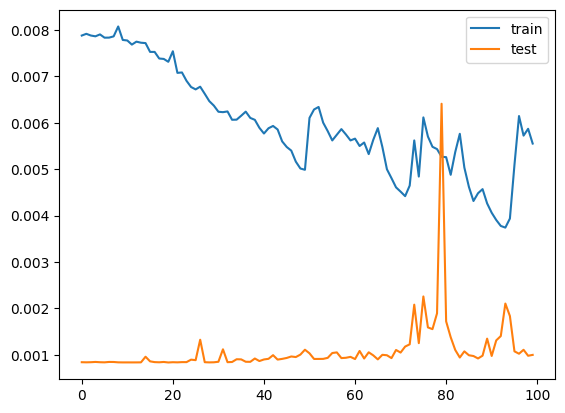

In [21]:
plt.plot(train_losses, label='train')
plt.plot(test_losses, label='test')
plt.legend()
plt.show()
